# IT3091 — Telco Customer Churn Prediction
## Random Forest Model Development
**Member:** IT24102178  
**Notebook:** `09_random_forest.ipynb`

---

### Experiment Plan
| Step | Configuration | Purpose |
|------|---------------|---------|
| 9.1 | Baseline features · No balancing | Reference starting point |
| 9.2 | Baseline features · class_weight="balanced" | Built-in imbalance handling |
| 9.3 | Baseline features · Random oversampling | Explicit resampling |
| 9.4 | Engineered features · No balancing | Feature engineering impact |
| 9.5 | Engineered features · class_weight="balanced" | Best combined strategy |
| 9.6 | Engineered features · Random oversampling | Feature + resampling |
| 9.7 | Hyperparameter tuning (n_estimators, max_depth, min_samples_leaf) | Grid search via CV |
| 9.8 | Summary comparison table | Select best configuration |
| 9.9 | Feature importance plot | Interpretability |
| 9.10 | Final test set evaluation | Held-out test evaluation |
| 9.11 | Save results and model | Persist outputs |

##### Cell 1 — Import shared functions and prepare data

In [1]:

# ==========================================================
# IT3091 - Telco Customer Churn
# Random Forest Model Development
# Member: IT24102178
# Step 9.1 - Setup and Data Preparation
# ==========================================================

import sys
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
import joblib

from src.data_preparation import (
    load_and_clean_data,
    separate_features_target
)
from src.validation import create_train_test_split
from src.imbalance import build_model_pipeline
from src.evaluation import evaluate_cv

# Load cleaned dataset
df = load_and_clean_data(project_root)

# Separate predictors and target
X, y = separate_features_target(df)

# Reuse shared 80/20 stratified split
X_train, X_test, y_train, y_test = create_train_test_split(X, y)

print("Random Forest imports successful!")
print("Training records:", len(X_train))
print("Testing records: ", len(X_test))
print("Training features:", X_train.shape[1])
print("Churn rate (train):", round(y_train.mean(), 4))


Random Forest imports successful!
Training records: 5634
Testing records:  1409
Training features: 19
Churn rate (train): 0.2654


##### Cell 2 — Step 9.1: Baseline features, no class balancing

In [2]:

# ==========================================================
# Step 9.1 — Baseline RF · No balancing
# scale_numeric=False (tree-based models do not require scaling)
# add_engineered_features=False
# imbalance_strategy="none"
# ==========================================================

rf_baseline_none = build_model_pipeline(
    model=RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    scale_numeric=False,
    add_engineered_features=False,
    imbalance_strategy="none"
)

print("Pipeline steps:", list(rf_baseline_none.named_steps.keys()))

results_91 = evaluate_cv(rf_baseline_none, X_train, y_train)
results_91.insert(0, "Configuration", "Baseline · No balancing")
display(results_91)


Pipeline steps: ['features', 'preprocessor', 'model']


,Configuration,Metric,Mean,Std
0,Baseline · No balancing,F1,0.5431,0.0163
1,Baseline · No balancing,Recall,0.4789,0.0124
2,Baseline · No balancing,Precision,0.6274,0.0244
3,Baseline · No balancing,ROC_AUC,0.8194,0.0113
4,Baseline · No balancing,Accuracy,0.7861,0.0089


##### Cell 3 — Step 9.2: Baseline features, class_weight="balanced"

In [3]:

# ==========================================================
# Step 9.2 — Baseline RF · class_weight="balanced"
# RandomForest natively supports class_weight.
# "balanced" adjusts weights inversely proportional to
# class frequencies in the input data.
# ==========================================================

rf_baseline_balanced = build_model_pipeline(
    model=RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    scale_numeric=False,
    add_engineered_features=False,
    imbalance_strategy="none"
)

results_92 = evaluate_cv(rf_baseline_balanced, X_train, y_train)
results_92.insert(0, "Configuration", "Baseline · class_weight=balanced")
display(results_92)


,Configuration,Metric,Mean,Std
0,Baseline · class_weight=balanced,F1,0.6015,0.0249
1,Baseline · class_weight=balanced,Recall,0.6435,0.0351
2,Baseline · class_weight=balanced,Precision,0.5648,0.0172
3,Baseline · class_weight=balanced,ROC_AUC,0.8219,0.0127
4,Baseline · class_weight=balanced,Accuracy,0.7741,0.0109


##### Cell 4 — Step 9.3: Baseline features, random oversampling

In [4]:

# ==========================================================
# Step 9.3 — Baseline RF · Random oversampling
# RandomOverSampler applied inside each CV fold
# via build_model_pipeline (training data only).
# ==========================================================

rf_baseline_ros = build_model_pipeline(
    model=RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    scale_numeric=False,
    add_engineered_features=False,
    imbalance_strategy="random_oversampling"
)

print("Pipeline steps:", list(rf_baseline_ros.named_steps.keys()))

results_93 = evaluate_cv(rf_baseline_ros, X_train, y_train)
results_93.insert(0, "Configuration", "Baseline · Random oversampling")
display(results_93)


Pipeline steps: ['features', 'preprocessor', 'sampler', 'model']


,Configuration,Metric,Mean,Std
0,Baseline · Random oversampling,F1,0.5685,0.0239
1,Baseline · Random oversampling,Recall,0.5565,0.0302
2,Baseline · Random oversampling,Precision,0.5814,0.0212
3,Baseline · Random oversampling,ROC_AUC,0.8155,0.0109
4,Baseline · Random oversampling,Accuracy,0.7760,0.0108


##### Cell 5 — Step 9.4: Engineered features, no class balancing

In [5]:

# ==========================================================
# Step 9.4 — Engineered features · No balancing
# add_engineered_features=True adds TenureGroup and
# ServiceCount. Preprocessor expands to 50 columns.
# ==========================================================

rf_eng_none = build_model_pipeline(
    model=RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    scale_numeric=False,
    add_engineered_features=True,
    imbalance_strategy="none"
)

results_94 = evaluate_cv(rf_eng_none, X_train, y_train)
results_94.insert(0, "Configuration", "Engineered · No balancing")
display(results_94)


,Configuration,Metric,Mean,Std
0,Engineered · No balancing,F1,0.5481,0.0206
1,Engineered · No balancing,Recall,0.4856,0.0172
2,Engineered · No balancing,Precision,0.6295,0.0321
3,Engineered · No balancing,ROC_AUC,0.8204,0.0112
4,Engineered · No balancing,Accuracy,0.7874,0.0115


##### Cell 6 — Step 9.5: Engineered features, class_weight="balanced"

In [6]:

# ==========================================================
# Step 9.5 — Engineered features · class_weight="balanced"
# ==========================================================

rf_eng_balanced = build_model_pipeline(
    model=RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    scale_numeric=False,
    add_engineered_features=True,
    imbalance_strategy="none"
)

results_95 = evaluate_cv(rf_eng_balanced, X_train, y_train)
results_95.insert(0, "Configuration", "Engineered · class_weight=balanced")
display(results_95)


,Configuration,Metric,Mean,Std
0,Engineered · class_weight=balanced,F1,0.6046,0.0199
1,Engineered · class_weight=balanced,Recall,0.6388,0.0288
2,Engineered · class_weight=balanced,Precision,0.5740,0.0137
3,Engineered · class_weight=balanced,ROC_AUC,0.8245,0.0125
4,Engineered · class_weight=balanced,Accuracy,0.7785,0.0087


##### Cell 7 — Step 9.6: Engineered features, random oversampling

In [7]:

# ==========================================================
# Step 9.6 — Engineered features · Random oversampling
# ==========================================================

rf_eng_ros = build_model_pipeline(
    model=RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    scale_numeric=False,
    add_engineered_features=True,
    imbalance_strategy="random_oversampling"
)

results_96 = evaluate_cv(rf_eng_ros, X_train, y_train)
results_96.insert(0, "Configuration", "Engineered · Random oversampling")
display(results_96)


,Configuration,Metric,Mean,Std
0,Engineered · Random oversampling,F1,0.5791,0.0248
1,Engineered · Random oversampling,Recall,0.5692,0.0287
2,Engineered · Random oversampling,Precision,0.5896,0.0222
3,Engineered · Random oversampling,ROC_AUC,0.8180,0.0098
4,Engineered · Random oversampling,Accuracy,0.7806,0.0117


In [8]:

# Compare the six initial Random Forest configurations

all_results = pd.concat(
    [results_91, results_92, results_93,
     results_94, results_95, results_96],
    ignore_index=True
)

initial_comparison = all_results.pivot_table(
    index="Configuration",
    columns="Metric",
    values="Mean"
).reset_index()

initial_comparison = initial_comparison.sort_values(
    "F1", ascending=False
)

display(initial_comparison)

print(
    "Best configuration:",
    initial_comparison.iloc[0]["Configuration"]
)


Metric,Configuration,Accuracy,F1,Precision,ROC_AUC,Recall
5,Engineered · class_weight=balanced,0.7785,0.6046,0.5740,0.8245,0.6388
2,Baseline · class_weight=balanced,0.7741,0.6015,0.5648,0.8219,0.6435
4,Engineered · Random oversampling,0.7806,0.5791,0.5896,0.8180,0.5692
1,Baseline · Random oversampling,0.7760,0.5685,0.5814,0.8155,0.5565
3,Engineered · No balancing,0.7874,0.5481,0.6295,0.8204,0.4856
0,Baseline · No balancing,0.7861,0.5431,0.6274,0.8194,0.4789


Best configuration: Engineered · class_weight=balanced


##### Cell 8 — Step 9.7: Hyperparameter tuning (n_estimators, max_depth, min_samples_leaf)

In [9]:

# ==========================================================
# Step 9.7 — Hyperparameter tuning
#
# We use the best imbalance strategy found in Steps 9.1–9.6
# and search over three key hyperparameters:
#   n_estimators   : number of trees
#   max_depth      : maximum depth per tree (None = unlimited)
#   min_samples_leaf: minimum samples required at leaf
#
# We iterate the parameter grid manually using evaluate_cv()
# to stay consistent with the shared evaluation framework.
# ==========================================================

param_grid = {
    "n_estimators":    [100, 200, 300],
    "max_depth":       [None, 10, 20],
    "min_samples_leaf": [1, 5, 10],
}

# Choose the imbalance strategy that performed best above.
# Inspect results_91–96 to select; default to "balanced" as
# a strong baseline. Update if needed after running cells above.
BEST_IMBALANCE   = "none"          # update after running steps 9.1-9.6
BEST_ENGINEERED  = True            # update after running steps 9.1-9.6
BEST_CLASS_WEIGHT = "balanced"     # update after running steps 9.1-9.6

tuning_records = []

for params in ParameterGrid(param_grid):
    model = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        class_weight=BEST_CLASS_WEIGHT,
        random_state=42,
        n_jobs=-1
    )
    pipeline = build_model_pipeline(
        model=model,
        scale_numeric=False,
        add_engineered_features=BEST_ENGINEERED,
        imbalance_strategy=BEST_IMBALANCE
    )
    cv_df = evaluate_cv(pipeline, X_train, y_train)
    f1_mean = cv_df.loc[cv_df["Metric"] == "F1", "Mean"].values[0]
    auc_mean = cv_df.loc[cv_df["Metric"] == "ROC_AUC", "Mean"].values[0]
    recall_mean = cv_df.loc[cv_df["Metric"] == "Recall", "Mean"].values[0]
    record = {
        "n_estimators":     params["n_estimators"],
        "max_depth":        str(params["max_depth"]),
        "min_samples_leaf": params["min_samples_leaf"],
        "F1":               f1_mean,
        "ROC_AUC":          auc_mean,
        "Recall":           recall_mean,
    }
    tuning_records.append(record)
    print(f"n_est={params['n_estimators']:3d}  "
          f"depth={str(params['max_depth']):4s}  "
          f"leaf={params['min_samples_leaf']:2d}  "
          f"F1={f1_mean:.4f}  AUC={auc_mean:.4f}")

tuning_df = pd.DataFrame(tuning_records).sort_values("F1", ascending=False)
display(tuning_df.head(10))

best_params = tuning_df.iloc[0]
print(f"\nBest hyperparameters (F1={best_params['F1']:.4f}):")
print(f"  n_estimators    = {int(best_params['n_estimators'])}")
print(f"  max_depth       = {best_params['max_depth']}")
print(f"  min_samples_leaf= {int(best_params['min_samples_leaf'])}")


n_est=100  depth=None  leaf= 1  F1=0.6046  AUC=0.8245
n_est=200  depth=None  leaf= 1  F1=0.6038  AUC=0.8267
n_est=300  depth=None  leaf= 1  F1=0.6077  AUC=0.8263
n_est=100  depth=None  leaf= 5  F1=0.6267  AUC=0.8434
n_est=200  depth=None  leaf= 5  F1=0.6288  AUC=0.8446
n_est=300  depth=None  leaf= 5  F1=0.6290  AUC=0.8449
n_est=100  depth=None  leaf=10  F1=0.6333  AUC=0.8469
n_est=200  depth=None  leaf=10  F1=0.6352  AUC=0.8476
n_est=300  depth=None  leaf=10  F1=0.6349  AUC=0.8476
n_est=100  depth=10    leaf= 1  F1=0.6258  AUC=0.8424
n_est=200  depth=10    leaf= 1  F1=0.6242  AUC=0.8430
n_est=300  depth=10    leaf= 1  F1=0.6264  AUC=0.8435
n_est=100  depth=10    leaf= 5  F1=0.6296  AUC=0.8450
n_est=200  depth=10    leaf= 5  F1=0.6316  AUC=0.8466
n_est=300  depth=10    leaf= 5  F1=0.6330  AUC=0.8466
n_est=100  depth=10    leaf=10  F1=0.6312  AUC=0.8474
n_est=200  depth=10    leaf=10  F1=0.6310  AUC=0.8478
n_est=300  depth=10    leaf=10  F1=0.6323  AUC=0.8479
n_est=100  depth=20    leaf=

,n_estimators,max_depth,min_samples_leaf,F1,ROC_AUC,Recall
7,200,None,10,0.6352,0.8476,0.7839
25,200,20,10,0.6352,0.8476,0.7839
8,300,None,10,0.6349,0.8476,0.7833
26,300,20,10,0.6349,0.8476,0.7833
24,100,20,10,0.6333,0.8469,0.7779
6,100,None,10,0.6333,0.8469,0.7779
14,300,10,5,0.6330,0.8466,0.7732
17,300,10,10,0.6323,0.8479,0.7813
13,200,10,5,0.6316,0.8466,0.7712
15,100,10,10,0.6312,0.8474,0.7773



Best hyperparameters (F1=0.6352):
  n_estimators    = 200
  max_depth       = None
  min_samples_leaf= 10


##### Cell 9 — Step 9.8: Summary comparison of all configurations

In [10]:

# ==========================================================
# Step 9.8 — Summary comparison table
# Includes the six feature × imbalance experiments.
# The tuned model result is appended separately below.
# ==========================================================

all_results = pd.concat(
    [results_91, results_92, results_93,
     results_94, results_95, results_96],
    ignore_index=True
)

summary = all_results.pivot_table(
    index="Configuration",
    columns="Metric",
    values="Mean"
).reset_index()

metric_cols = [c for c in ["F1", "Recall", "Precision", "ROC_AUC", "Accuracy"]
               if c in summary.columns]
summary = summary[["Configuration"] + metric_cols]

best_idx = summary["F1"].idxmax()
print(f"Best base configuration (F1): {summary.loc[best_idx, 'Configuration']}")
print(f"Best F1 mean:                 {summary.loc[best_idx, 'F1']:.4f}")
print()
display(summary.sort_values("F1", ascending=False))

# Save to results/tables/
tables_dir = project_root / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
summary.to_csv(tables_dir / "random_forest_cv.csv", index=False)
tuning_df.to_csv(tables_dir / "random_forest_tuning.csv", index=False)
print("CV results saved to results/tables/random_forest_cv.csv")
print("Tuning results saved to results/tables/random_forest_tuning.csv")


Best base configuration (F1): Engineered · class_weight=balanced
Best F1 mean:                 0.6046



Metric,Configuration,F1,Recall,Precision,ROC_AUC,Accuracy
5,Engineered · class_weight=balanced,0.6046,0.6388,0.5740,0.8245,0.7785
2,Baseline · class_weight=balanced,0.6015,0.6435,0.5648,0.8219,0.7741
4,Engineered · Random oversampling,0.5791,0.5692,0.5896,0.8180,0.7806
1,Baseline · Random oversampling,0.5685,0.5565,0.5814,0.8155,0.7760
3,Engineered · No balancing,0.5481,0.4856,0.6295,0.8204,0.7874
0,Baseline · No balancing,0.5431,0.4789,0.6274,0.8194,0.7861


CV results saved to results/tables/random_forest_cv.csv
Tuning results saved to results/tables/random_forest_tuning.csv


##### Cell 10 — Step 9.8b: Bar chart — F1 comparison across configurations

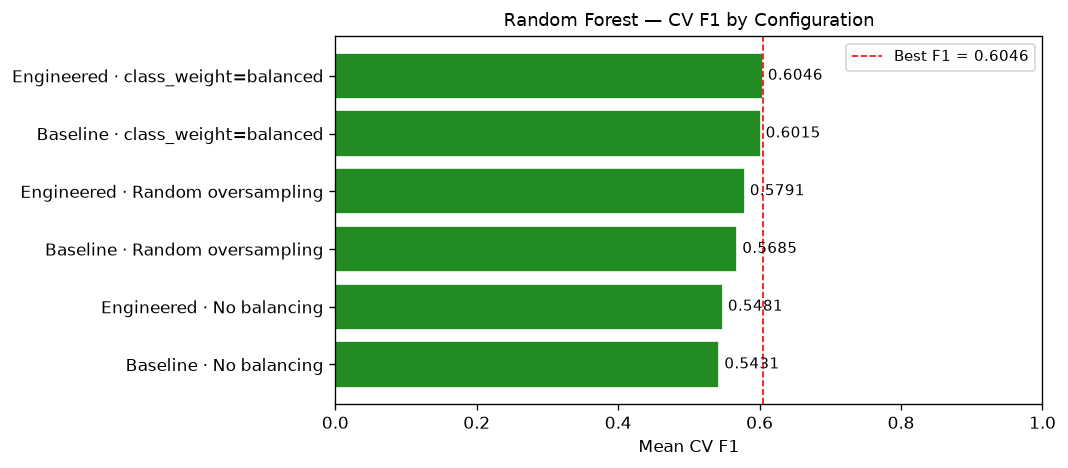

Figure saved to results/figures/random_forest/rf_cv_f1_comparison.png


In [11]:

# ==========================================================
# Step 9.8b — Bar chart: F1 by configuration
# ==========================================================

figures_dir = project_root / "results" / "figures" / "random_forest"
figures_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 4))

configs = summary.sort_values("F1", ascending=True)["Configuration"]
f1_vals = summary.sort_values("F1", ascending=True)["F1"]

bars = ax.barh(configs, f1_vals, color="forestgreen", edgecolor="white")
ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
ax.set_xlabel("Mean CV F1")
ax.set_title("Random Forest — CV F1 by Configuration", fontsize=11)
ax.set_xlim(0, 1.0)
ax.axvline(x=f1_vals.max(), color="red", linestyle="--", linewidth=1,
           label=f"Best F1 = {f1_vals.max():.4f}")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(figures_dir / "rf_cv_f1_comparison.png", bbox_inches="tight")
plt.show()
print("Figure saved to results/figures/random_forest/rf_cv_f1_comparison.png")


##### Cell 11 — Step 9.9: Feature importance plot (best tuned model)

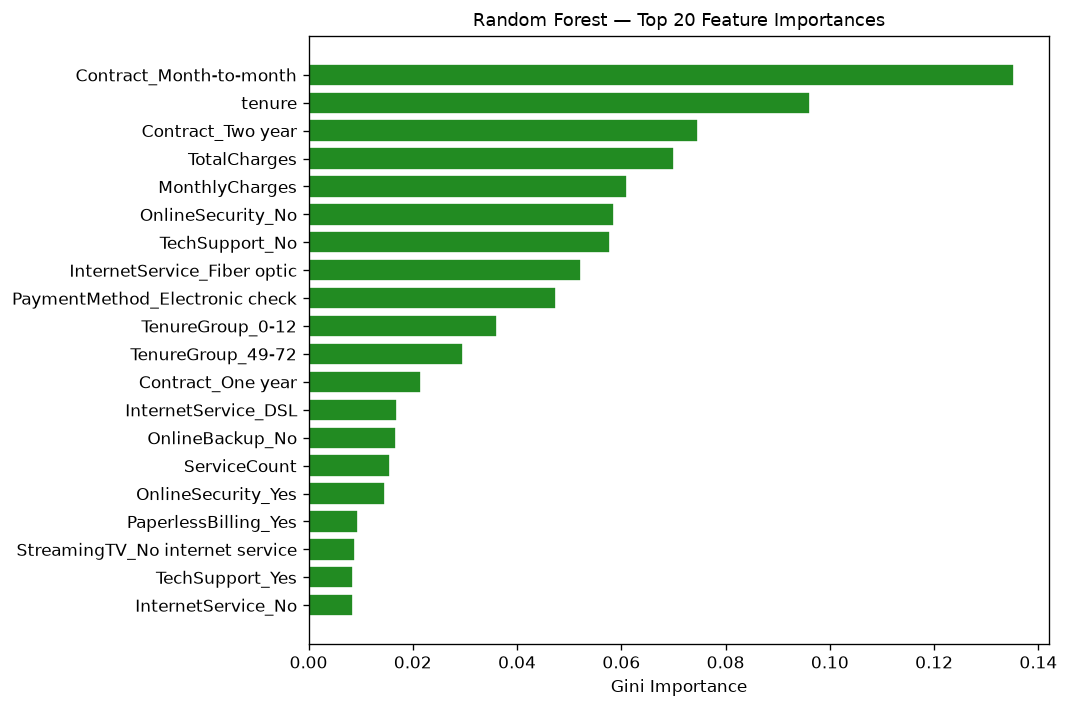

Figure saved to results/figures/random_forest/rf_feature_importance.png


In [12]:

# ==========================================================
# Step 9.9 — Feature importance (Gini impurity based)
#
# We build the tuned pipeline using the best parameters
# found in Step 9.7, retrain on the full training set,
# then extract feature importances.
# ==========================================================

best_n_est  = int(best_params["n_estimators"])
best_depth  = None if best_params["max_depth"] == "None" else int(best_params["max_depth"])
best_leaf   = int(best_params["min_samples_leaf"])

rf_tuned = build_model_pipeline(
    model=RandomForestClassifier(
        n_estimators=best_n_est,
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        class_weight=BEST_CLASS_WEIGHT,
        random_state=42,
        n_jobs=-1
    ),
    scale_numeric=False,
    add_engineered_features=BEST_ENGINEERED,
    imbalance_strategy=BEST_IMBALANCE
)

# Fit tuned pipeline on full training set for feature importance
rf_tuned.fit(X_train, y_train)

# Extract feature names from preprocessor output
preprocessor = rf_tuned.named_steps["preprocessor"]
try:
    feature_names = preprocessor.get_feature_names_out()
except Exception:
    feature_names = [f"feature_{i}" for i in range(
        rf_tuned.named_steps["model"].n_features_in_)]

importances = rf_tuned.named_steps["model"].feature_importances_
fi_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
).sort_values("Importance", ascending=False).head(20)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(fi_df["Feature"][::-1], fi_df["Importance"][::-1],
        color="forestgreen", edgecolor="white")
ax.set_xlabel("Gini Importance")
ax.set_title("Random Forest — Top 20 Feature Importances", fontsize=11)
plt.tight_layout()
plt.savefig(figures_dir / "rf_feature_importance.png", bbox_inches="tight")
plt.show()
print("Figure saved to results/figures/random_forest/rf_feature_importance.png")


In [13]:

# Save the tuned Random Forest CV performance
# for comparison against Logistic Regression, SVM and GB

rf_final_cv = evaluate_cv(
    rf_tuned,
    X_train,
    y_train
)

display(rf_final_cv)

rf_final_cv.to_csv(
    tables_dir / "random_forest_final_cv.csv",
    index=False
)

print("Final tuned Random Forest CV results saved.")


,Metric,Mean,Std
0,F1,0.6352,0.0164
1,Recall,0.7839,0.0260
2,Precision,0.5342,0.0157
3,ROC_AUC,0.8476,0.0107
4,Accuracy,0.7611,0.0118


Final tuned Random Forest CV results saved.


##### Cell 12 — Step 9.10: Evaluate tuned model on held-out test set

In [14]:

# ==========================================================
# Step 9.10 — Final test set evaluation
#
# rf_tuned was already fitted on X_train in Cell 11.
# IMPORTANT: The test set is accessed only once here.
# ==========================================================

y_pred  = rf_tuned.predict(X_test)
y_proba = rf_tuned.predict_proba(X_test)[:, 1]

print("=" * 55)
print("HELD-OUT TEST SET EVALUATION — Random Forest")
print(f"Configuration: n_est={best_n_est}, "
      f"depth={best_depth}, leaf={best_leaf}, "
      f"class_weight={BEST_CLASS_WEIGHT}")
print("=" * 55)
print(classification_report(y_test, y_pred,
                             target_names=["No Churn", "Churn"]))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")


HELD-OUT TEST SET EVALUATION — Random Forest
Configuration: n_est=200, depth=None, leaf=10, class_weight=balanced
              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.82      1035
       Churn       0.53      0.80      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409

ROC-AUC: 0.8454


##### Cell 13 — Confusion matrix and ROC curve for best model

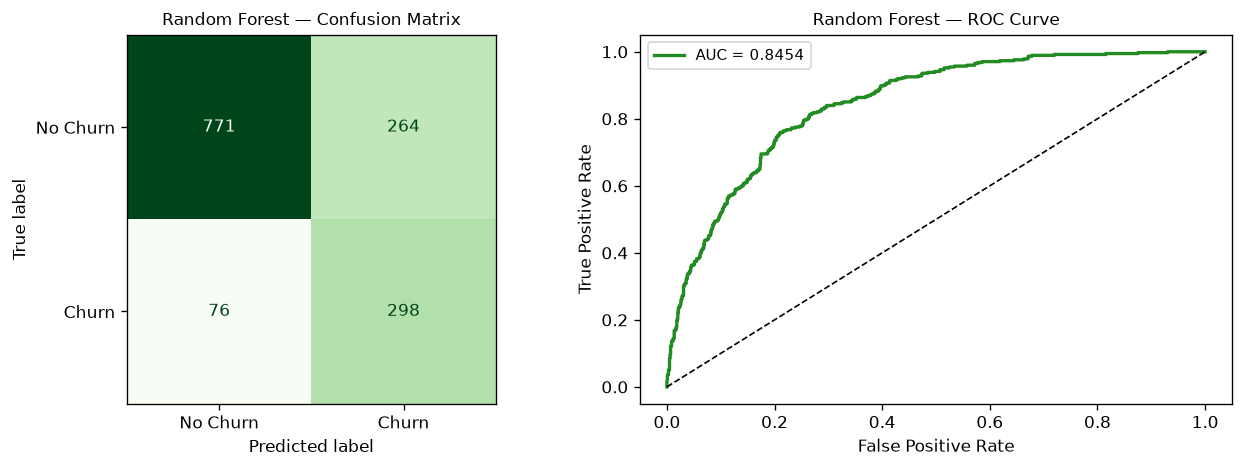

Figure saved to results/figures/random_forest/rf_test_cm_roc.png


In [15]:

# ==========================================================
# Confusion matrix and ROC curve — test set
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)
disp.plot(ax=axes[0], colorbar=False, cmap="Greens")
axes[0].set_title("Random Forest — Confusion Matrix", fontsize=10)

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)
axes[1].plot(fpr, tpr, color="forestgreen", lw=2,
             label=f"AUC = {auc_score:.4f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Random Forest — ROC Curve", fontsize=10)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / "rf_test_cm_roc.png", bbox_inches="tight")
plt.show()
print("Figure saved to results/figures/random_forest/rf_test_cm_roc.png")


##### Cell 14 — Step 9.11: Save final test metrics and model

In [16]:

# ==========================================================
# Step 9.11 — Save results and model
# ==========================================================

from sklearn.metrics import f1_score, recall_score, precision_score, accuracy_score

best_config_label = (
    f"Tuned RF · n_est={best_n_est}, "
    f"depth={best_depth}, leaf={best_leaf}"
)

test_metrics = pd.DataFrame([
    {"Metric": "F1",        "Value": round(f1_score(y_test, y_pred), 4)},
    {"Metric": "Recall",    "Value": round(recall_score(y_test, y_pred), 4)},
    {"Metric": "Precision", "Value": round(precision_score(y_test, y_pred), 4)},
    {"Metric": "ROC_AUC",   "Value": round(roc_auc_score(y_test, y_proba), 4)},
    {"Metric": "Accuracy",  "Value": round(accuracy_score(y_test, y_pred), 4)},
])

test_metrics.insert(0, "Model", "Random Forest")
test_metrics.insert(1, "Configuration", best_config_label)

display(test_metrics)

# Save test metrics
test_metrics.to_csv(
    tables_dir / "random_forest_test_metrics.csv",
    index=False
)
print("Test metrics saved to results/tables/random_forest_test_metrics.csv")

# Save model
models_dir = project_root / "results" / "models"
models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(rf_tuned, models_dir / "random_forest.joblib")
print("Model saved to results/models/random_forest.joblib")


,Model,Configuration,Metric,Value
0,Random Forest,"Tuned RF · n_est=200, depth=None, leaf=10",F1,0.6368
1,Random Forest,"Tuned RF · n_est=200, depth=None, leaf=10",Recall,0.7968
2,Random Forest,"Tuned RF · n_est=200, depth=None, leaf=10",Precision,0.5302
3,Random Forest,"Tuned RF · n_est=200, depth=None, leaf=10",ROC_AUC,0.8454
4,Random Forest,"Tuned RF · n_est=200, depth=None, leaf=10",Accuracy,0.7587


Test metrics saved to results/tables/random_forest_test_metrics.csv
Model saved to results/models/random_forest.joblib
